# Multi-label classification of Amazon satellite images

The **Planet Amazon** dataset contains about **40,000 satellite chips** (256×256 px JPG). Each image can have several labels at the same time. From the 17 original labels we keep **5 targets**: `primary` (primary forest), `water`, `agriculture`, `road` and `cloudy`.

Instead of feeding raw pixels to a neural network, each image is described by **25 hand-crafted numbers** (colour, vegetation, texture, edges and local patches). This keeps the model small and every decision explainable.

**How the evaluation is kept honest**

| Split | Share | Used for |
|---|---|---|
| Train | 60% | fitting the models |
| Validation | 20% | choosing the model, the hyperparameters and the decision thresholds |
| Test | 20% | measured **once**, at the very end |

If we chose the model by looking at the test set, the test score would be like a student who has seen the exam questions: optimistic. All decisions here are made on validation.

## 0. Setup

In [1]:
import json
import sys
import time
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from tqdm import tqdm

from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import f1_score, fbeta_score, make_scorer, multilabel_confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

sys.path.insert(0, str(Path('../src').resolve()))
from features import extract_features, FEATURE_NAMES, GLOBAL_FEATURES

SEED = 42
SEEDS = [0, 1, 2]          # repeated runs, to tell real gains from noise
np.random.seed(SEED)

DATA_DIR   = Path('../data/raw/planet')
IMG_DIR    = DATA_DIR / 'train-jpg'
LABELS_CSV = DATA_DIR / 'train_classes.csv'
FIG_DIR    = Path('../figures');  FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR  = Path('../models');   MODEL_DIR.mkdir(exist_ok=True)

TARGET_LABELS = ['primary', 'water', 'agriculture', 'road', 'cloudy']

# Same palette as the demo
COLORS = {'primary': '#4A6175', 'water': '#7BB3D9', 'agriculture': '#D6CF95',
          'road': '#9C9492', 'cloudy': '#A893AE'}
INK, GREY, MIST = '#2F4253', '#6F6A64', '#C6E3C6'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': GREY, 'axes.labelcolor': INK, 'text.color': INK,
                     'xtick.color': GREY, 'ytick.color': GREY, 'figure.dpi': 110})

def macro_f1(Y_true, Y_pred):
    return f1_score(Y_true, Y_pred, average='macro', zero_division=0)

def per_label_f1(Y_true, Y_pred):
    return f1_score(Y_true, Y_pred, average=None, zero_division=0)

def predict_proba(model, X):
    # Probability of "label present" for each of the 5 labels -> shape (n, 5)
    return np.column_stack([est.predict_proba(X)[:, 1] for est in model.estimators_])

## 1. Exploratory data analysis

In [2]:
df_raw = pd.read_csv(LABELS_CSV)
print(f'Images: {len(df_raw)}')
df_raw.head()

Images: 40479


,image_name,tags
0,train_0,haze primary
1,train_1,agriculture clear primary water
2,train_2,clear primary
3,train_3,clear primary
4,train_4,agriculture clear habitation primary road


17 original labels: ['agriculture', 'artisinal_mine', 'bare_ground', 'blooming', 'blow_down', 'clear', 'cloudy', 'conventional_mine', 'cultivation', 'habitation', 'haze', 'partly_cloudy', 'primary', 'road', 'selective_logging', 'slash_burn', 'water']
primary        0.927
agriculture    0.304
road           0.199
water          0.183
cloudy         0.052


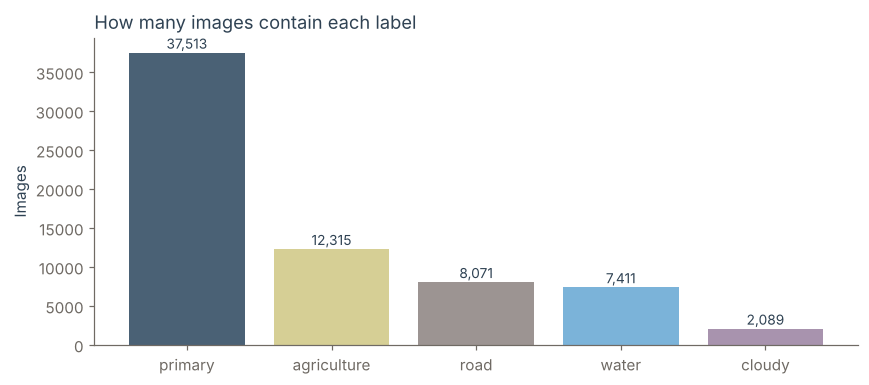

In [3]:
all_labels = sorted({t for tags in df_raw['tags'] for t in tags.split()})
print(f'{len(all_labels)} original labels: {all_labels}')

for lbl in TARGET_LABELS:
    df_raw[lbl] = df_raw['tags'].apply(lambda t: int(lbl in t.split()))

freq = df_raw[TARGET_LABELS].sum().sort_values(ascending=False)
print((freq / len(df_raw)).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(freq.index, freq.values, color=[COLORS[l] for l in freq.index])
for i, v in enumerate(freq.values):
    ax.text(i, v + 500, f'{v:,}', ha='center', fontsize=9, color=INK)
ax.set_title('How many images contain each label', loc='left')
ax.set_ylabel('Images')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig1_label_frequency.png', dpi=150, bbox_inches='tight')
plt.show()

The labels are very **unbalanced**: 93% of the images contain primary forest and only 5% are cloudy. A model can look good just by always saying "primary", so the metrics below give each label the same weight.

In [4]:
df_raw['n_target_labels'] = df_raw[TARGET_LABELS].sum(axis=1)
print(f"Average target labels per image: {df_raw['n_target_labels'].mean():.2f}")
print(df_raw['n_target_labels'].value_counts().sort_index().to_string())

Average target labels per image: 1.67
n_target_labels
0       86
1    22827
2     9252
3     7188
4     1126


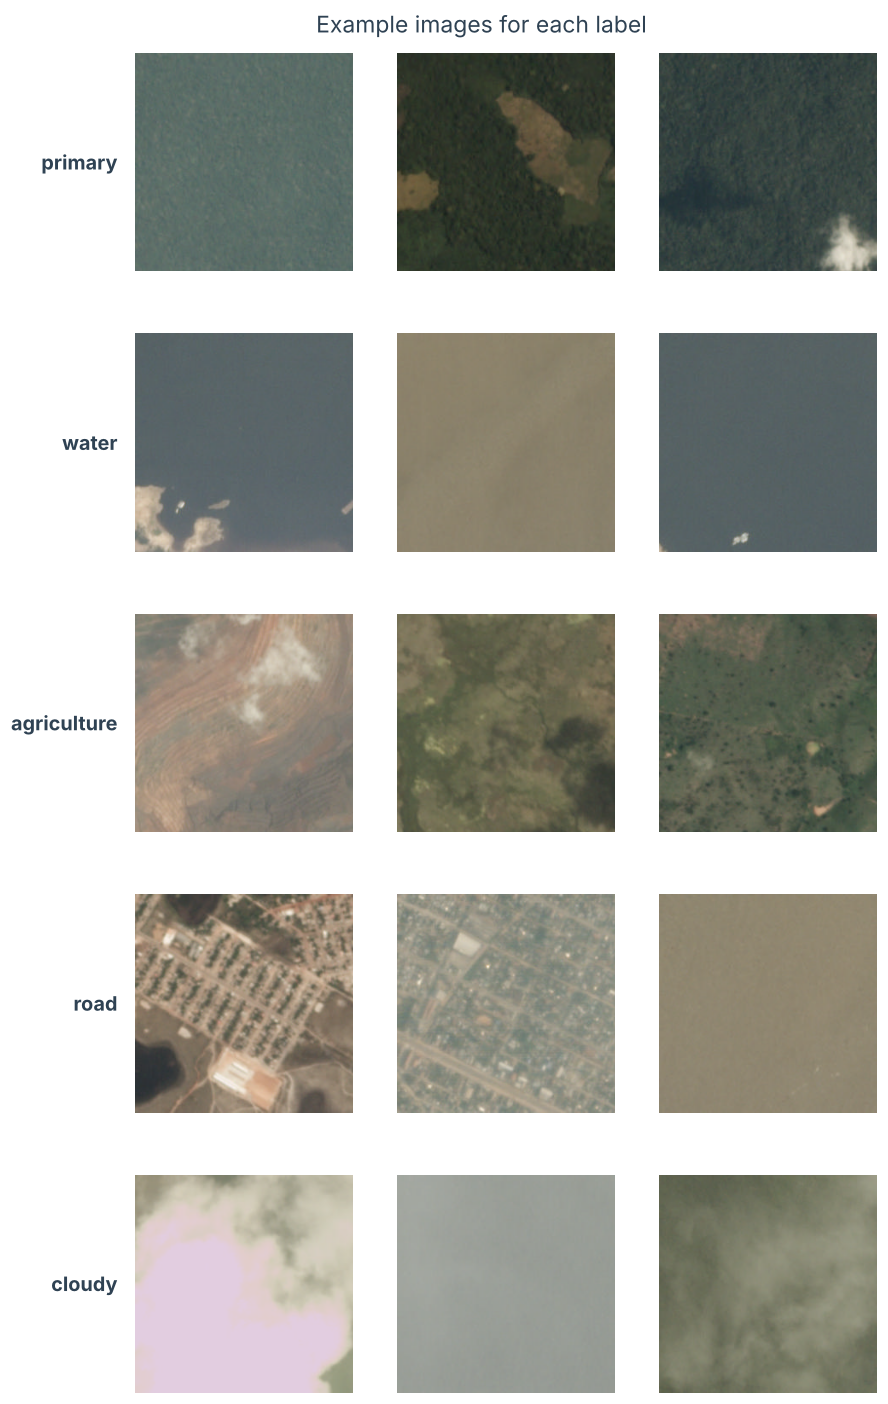

In [5]:
# Three images per label that contain only that target label
N_PER_LABEL = 3
df_eda = df_raw[df_raw['n_target_labels'] > 0]

fig, axes = plt.subplots(len(TARGET_LABELS), N_PER_LABEL, figsize=(9, 16))
plt.subplots_adjust(left=0.15)
for row_i, lbl in enumerate(TARGET_LABELS):
    others = [l for l in TARGET_LABELS if l != lbl]
    pure = (df_eda[(df_eda[lbl] == 1) & (df_eda[others].sum(axis=1) == 0)]
            .sort_values('image_name').reset_index(drop=True))
    step = len(pure) // N_PER_LABEL
    for col_i in range(N_PER_LABEL):
        name = pure.iloc[col_i * step]['image_name']
        ax = axes[row_i, col_i]
        ax.imshow(Image.open(IMG_DIR / f'{name}.jpg').convert('RGB'))
        ax.axis('off')
        if col_i == 0:
            ax.text(-0.08, 0.5, lbl, transform=ax.transAxes, fontsize=13,
                    fontweight='bold', va='center', ha='right', color=INK)
plt.suptitle('Example images for each label', fontsize=15, y=0.90)
plt.savefig(FIG_DIR / 'fig2_label_examples.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Train / validation / test split

In [6]:
# Keep images with at least one target label
df = df_raw[df_raw['n_target_labels'] > 0].reset_index(drop=True)
print(f'Images kept: {len(df)}  (removed {len(df_raw) - len(df)} with no target label)')

names = df['image_name'].values
Y     = df[TARGET_LABELS].values

def strat_key(Y):
    # Stratify on the full label combination, so rare combinations appear in every split
    key = [''.join(map(str, row)) for row in Y]
    counts = Counter(key)
    return [k if counts[k] >= 2 else 'other' for k in key]

# 1) 20% test, set aside until the end
idx_rest, idx_test = train_test_split(np.arange(len(df)), test_size=0.20,
                                      random_state=SEED, stratify=strat_key(Y))
# 2) the rest -> 75% train / 25% validation (= 60% / 20% of the total)
idx_train, idx_val = train_test_split(idx_rest, test_size=0.25, random_state=SEED,
                                      stratify=strat_key(Y[idx_rest]))

Y_train, Y_val, Y_test = Y[idx_train], Y[idx_val], Y[idx_test]
print(f'Train: {len(idx_train)}   Validation: {len(idx_val)}   Test: {len(idx_test)}')
print()
print(pd.DataFrame({'train': Y_train.mean(0), 'val': Y_val.mean(0), 'test': Y_test.mean(0)},
                   index=TARGET_LABELS).round(3).to_string())

Images kept: 40393  (removed 86 with no target label)


Train: 24235   Validation: 8079   Test: 8079

             train    val   test
primary      0.929  0.929  0.929
water        0.183  0.184  0.183
agriculture  0.305  0.305  0.305
road         0.200  0.200  0.200
cloudy       0.052  0.052  0.052


## 3. Feature extraction

`src/features.py` turns each image into 25 numbers. The demo uses the **same file**, so training and prediction can never drift apart.

| Group | Features | Why |
|---|---|---|
| Colour (RGB, HSV) | mean and std of each channel | water, soil and forest have different colours |
| Vegetation | ExG = 2G − R − B | positive on dense vegetation |
| Texture | spread of brightness inside 8×8 patches | forest is rough, water is smooth |
| Ratios | R/G, G/B | canopy vs water |
| Entropy | of the brightness histogram | uniform vs chaotic image |
| **Edges** (new) | Sobel magnitude: mean, std, share of strong edges | roads and river banks are sharp lines |
| **Extreme patches** (new) | darkest/brightest patch, least/most green patch | a thin river or road disappears in a whole-image average but not in its own patch |

The first 18 are the original global features; the last 7 are new and target the weak labels, `water` and `road`.

In [7]:
t0 = time.time()
X_all = np.vstack([extract_features(IMG_DIR / f'{n}.jpg') for n in tqdm(names, desc='Extracting features')])
print(f'Feature matrix: {X_all.shape}  ({time.time() - t0:.0f} s)')

X_train_raw, X_val_raw, X_test_raw = X_all[idx_train], X_all[idx_val], X_all[idx_test]
G = len(GLOBAL_FEATURES)   # first 18 columns = original global features

# Standardise with statistics learned on train only (no leakage)
scaler = StandardScaler().fit(X_train_raw)
X_train, X_val, X_test = (scaler.transform(X) for X in (X_train_raw, X_val_raw, X_test_raw))

Extracting features:   0%|          | 0/40393 [00:00<?, ?it/s]

Extracting features:   0%|          | 22/40393 [00:00<03:14, 207.70it/s]

Extracting features:   0%|          | 43/40393 [00:00<03:40, 183.21it/s]

Extracting features:   0%|          | 62/40393 [00:00<03:50, 175.02it/s]

Extracting features:   0%|          | 80/40393 [00:00<04:11, 160.57it/s]

...

Extracting features: 100%|█████████▉| 40345/40393 [03:42<00:00, 178.83it/s]

Extracting features: 100%|█████████▉| 40365/40393 [03:43<00:00, 184.17it/s]

Extracting features: 100%|█████████▉| 40384/40393 [03:43<00:00, 184.91it/s]

Extracting features: 100%|██████████| 40393/40393 [03:43<00:00, 180.96it/s]

Feature matrix: (40393, 25)  (223 s)


## 4. PCA: are 25 features redundant?

PCA is unsupervised: it never looks at the labels. It finds directions that summarise most of the variance.

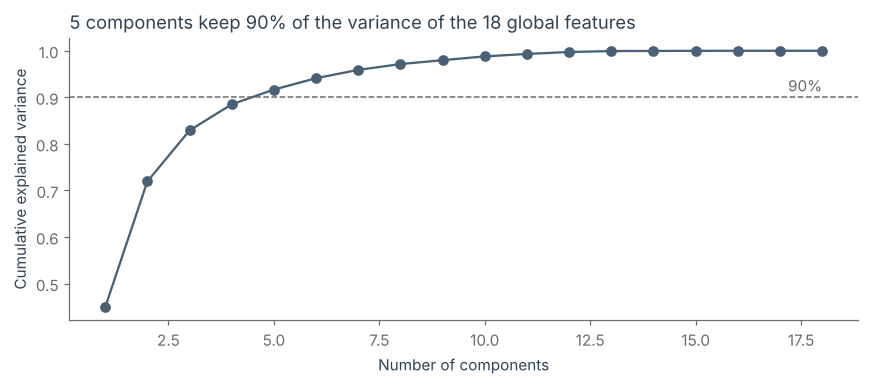

In [8]:
pca_full = PCA(random_state=SEED).fit(X_train[:, :G])
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
N_COMPONENTS = int(np.argmax(cumulative >= 0.90)) + 1

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(1, G + 1), cumulative, marker='o', color='#4A6175')
ax.axhline(0.90, color=GREY, linestyle='--', linewidth=1)
ax.text(G, 0.905, '90%', ha='right', va='bottom', color=GREY)
ax.set_xlabel('Number of components'); ax.set_ylabel('Cumulative explained variance')
ax.set_title(f'{N_COMPONENTS} components keep 90% of the variance of the 18 global features', loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig3_pca_variance.png', dpi=150, bbox_inches='tight')
plt.show()

pca = PCA(n_components=N_COMPONENTS, random_state=SEED).fit(X_train[:, :G])

## 5. A "lazy" baseline

Before training anything: what score do we get by always predicting the most common answer for each label (always "primary", never anything else)? Like a weather forecaster in the desert who always says "sunny": often right, but useless. Every model has to beat this.

In [9]:
majority = (Y_train.mean(0) >= 0.5).astype(int)
Y_dummy = np.tile(majority, (len(Y_val), 1))
print('Lazy baseline on validation')
for lbl, f in zip(TARGET_LABELS, per_label_f1(Y_val, Y_dummy)):
    print(f'  {lbl:<12} F1 = {f:.3f}')
print(f'  {"MACRO":<12} F1 = {macro_f1(Y_val, Y_dummy):.3f}')

Lazy baseline on validation
  primary      F1 = 0.963
  water        F1 = 0.000
  agriculture  F1 = 0.000
  road         F1 = 0.000
  cloudy       F1 = 0.000
  MACRO        F1 = 0.193


`primary` already scores about 0.96 without any learning, so a high F1 on that label says little. **Macro F1** (the plain average over the 5 labels) is the main metric: `water` counts as much as `primary`.

## 6. Model comparison on validation

Every model is trained **3 times with different random seeds** and we report mean ± standard deviation. A difference smaller than the spread between seeds is probably noise.

In [10]:
def rf(seed, balanced=False, **kw):
    return MultiOutputClassifier(RandomForestClassifier(
        n_estimators=200, class_weight='balanced' if balanced else None,
        random_state=seed, n_jobs=-1, **kw))

def xgb(seed):
    return MultiOutputClassifier(XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1, random_state=seed,
        eval_metric='logloss', verbosity=0, n_jobs=-1))

# Isolation Forest anomaly score as an extra feature (unsupervised, fit on train only)
iso = IsolationForest(contamination=0.05, random_state=SEED, n_jobs=-1).fit(X_train)
score = lambda X: -iso.score_samples(X).reshape(-1, 1)   # higher = more unusual
X_train_a, X_val_a, X_test_a = (np.hstack([X, score(X)]) for X in (X_train, X_val, X_test))

# Feature sets: name -> (train, validation, test, feature names)
FEATURE_SETS = {
    '18 global':           (X_train[:, :G], X_val[:, :G], X_test[:, :G], FEATURE_NAMES[:G]),
    '18 global -> PCA':    tuple(pca.transform(X[:, :G]) for X in (X_train, X_val, X_test)) + ([f'PC{i+1}' for i in range(N_COMPONENTS)],),
    '25':                  (X_train, X_val, X_test, FEATURE_NAMES),
    '25 + anomaly score':  (X_train_a, X_val_a, X_test_a, FEATURE_NAMES + ['anomaly_score']),
}

# name: (model factory, feature set)
experiments = {
    'RF':                          (lambda s: rf(s),                '18 global'),
    'RF + PCA':                    (lambda s: rf(s),                '18 global -> PCA'),
    'XGBoost':                     (lambda s: xgb(s),               '18 global'),
    'RF balanced':                 (lambda s: rf(s, balanced=True), '18 global'),
    'RF balanced + new features':  (lambda s: rf(s, balanced=True), '25'),
    'RF balanced + new features + anomaly score': (lambda s: rf(s, balanced=True), '25 + anomaly score'),
}

results = {}
for name, (make, fs) in experiments.items():
    Xtr, Xva = FEATURE_SETS[fs][:2]
    t0 = time.time()
    runs = []
    for s in SEEDS:
        model = make(s).fit(Xtr, Y_train)
        runs.append(per_label_f1(Y_val, model.predict(Xva)))
    runs = np.array(runs)
    results[name] = runs
    print(f'{name:<45} macro F1 = {runs.mean(1).mean():.4f} ± {runs.mean(1).std():.4f}   ({time.time() - t0:.0f} s)')

RF                                            macro F1 = 0.7227 ± 0.0015   (159 s)


RF + PCA                                      macro F1 = 0.6555 ± 0.0006   (84 s)


XGBoost                                       macro F1 = 0.7336 ± 0.0000   (13 s)


RF balanced                                   macro F1 = 0.7566 ± 0.0004   (138 s)


RF balanced + new features                    macro F1 = 0.7665 ± 0.0014   (155 s)


RF balanced + new features + anomaly score    macro F1 = 0.7677 ± 0.0015   (156 s)


In [11]:
summary = pd.DataFrame({name: r.mean(0) for name, r in results.items()}, index=TARGET_LABELS).T
summary['MACRO'] = [r.mean(1).mean() for r in results.values()]
summary['± std'] = [r.mean(1).std() for r in results.values()]
summary.round(4)

,primary,water,agriculture,road,cloudy,MACRO,± std
RF,0.9808,0.4970,0.7780,0.6034,0.7543,0.7227,0.0015
RF + PCA,0.9781,0.3422,0.7086,0.5315,0.7169,0.6555,0.0006
XGBoost,0.9814,0.5154,0.7875,0.6154,0.7681,0.7336,0.0000
RF balanced,0.9781,0.5854,0.7928,0.6502,0.7766,0.7566,0.0004
RF balanced + new features,0.9799,0.6023,0.7951,0.6605,0.7947,0.7665,0.0014
RF balanced + new features + anomaly score,0.9800,0.6048,0.7953,0.6591,0.7994,0.7677,0.0015


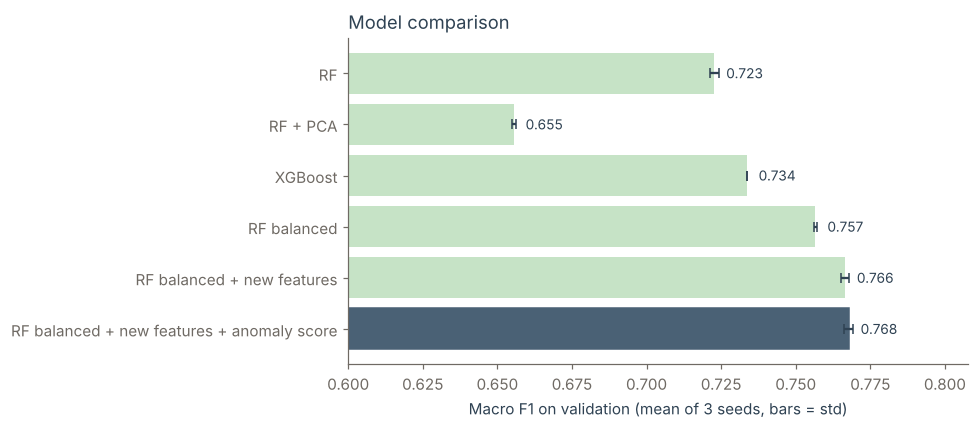

Best on validation: RF balanced + new features + anomaly score


In [12]:
names_ = list(results)
means  = [results[n].mean(1).mean() for n in names_]
stds   = [results[n].mean(1).std() for n in names_]
best_name = names_[int(np.argmax(means))]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(names_[::-1], means[::-1], xerr=stds[::-1], color=MIST, edgecolor='none',
               error_kw={'ecolor': INK, 'capsize': 3})
bars[names_[::-1].index(best_name)].set_color('#4A6175')
for y, m in enumerate(means[::-1]):
    ax.text(m + 0.004, y, f'{m:.3f}', va='center', fontsize=9)
ax.set_xlim(0.6, max(means) + 0.04)
ax.set_xlabel('Macro F1 on validation (mean of 3 seeds, bars = std)')
ax.set_title('Model comparison', loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig4_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Best on validation: {best_name}')

**What the comparison shows**
- **Class weights help the rare labels the most**: from RF to RF balanced, macro F1 goes from 0.723 to 0.757, with `water` +0.09 and `road` +0.05. Without weights, the forest learns that "no water" is almost always right.
- **PCA hurts** (0.655): the 10% of variance it throws away contains exactly the signal that separates water and roads.
- **XGBoost** beats the plain RF but not the balanced one.
- **The new edge and patch features help** (+0.010, about 7 times the spread between seeds), mostly on `water`, `road` and `cloudy`.
- **The anomaly score adds almost nothing** (+0.001, about the same size as the noise). It is kept because it was the best on validation and it is needed anyway for the demo warning, but it is not a real improvement.

## 7. Hyperparameter tuning (cross-validation on train)

Grid search with 3-fold cross-validation **inside the training set**. `min_samples_leaf` also matters for deployment: bigger leaves give a much smaller model file.

In [13]:
# The final model is the best balanced Random Forest variant, with its feature set
rf_variants = [n for n in results if n.startswith('RF balanced')]
final_name = max(rf_variants, key=lambda n: results[n].mean(1).mean())
Xtr_final, Xva_final, Xte_final, feat_names = FEATURE_SETS[experiments[final_name][1]]
print(f'Final model: {final_name}  ({len(feat_names)} features)')

param_grid = {'estimator__max_depth': [None, 20], 'estimator__min_samples_leaf': [1, 3, 5]}
gs = GridSearchCV(
    MultiOutputClassifier(RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                                 random_state=SEED, n_jobs=-1)),
    param_grid, cv=3, scoring=make_scorer(f1_score, average='macro', zero_division=0), n_jobs=1)
gs.fit(Xtr_final, Y_train)

cv = pd.DataFrame(gs.cv_results_)[['param_estimator__max_depth', 'param_estimator__min_samples_leaf',
                                   'mean_test_score', 'std_test_score']]
cv.columns = ['max_depth', 'min_samples_leaf', 'CV macro F1', 'std']
print(cv.sort_values('CV macro F1', ascending=False).round(4).to_string(index=False))
best_params = {k.replace('estimator__', ''): v for k, v in gs.best_params_.items()}
print('\nBest parameters:', best_params)

Final model: RF balanced + new features + anomaly score  (26 features)


max_depth  min_samples_leaf  CV macro F1    std
       20                 1       0.7575 0.0041
     None                 1       0.7570 0.0055
       20                 3       0.7570 0.0057
     None                 3       0.7570 0.0042
     None                 5       0.7508 0.0028
       20                 5       0.7500 0.0033

Best parameters: {'max_depth': 20, 'min_samples_leaf': 1}


In [14]:
final_model = rf(SEED, balanced=True, **best_params).fit(Xtr_final, Y_train)
P_val = predict_proba(final_model, Xva_final)
print(f'Validation macro F1 (threshold 0.5): {macro_f1(Y_val, (P_val >= 0.5).astype(int)):.4f}')

Validation macro F1 (threshold 0.5): 0.7655


## 8. One decision threshold per label

By default a label is "present" when its probability is ≥ 0.5. But that is like using the same pass mark for an easy exam and a very hard one. For a rare, hard label such as `water`, the model is rarely very confident, so a different threshold may find more true positives for a few extra false alarms.

For each label we try thresholds from 0.05 to 0.95 **on validation** and keep the one with the best F1.

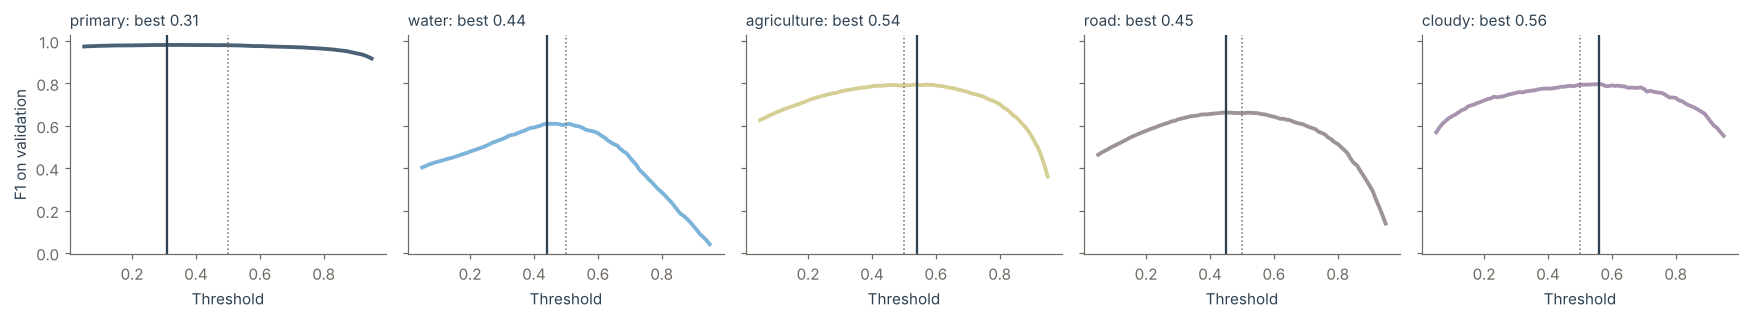

             threshold  F1 @ 0.5  F1 @ tuned
primary           0.31     0.980       0.981
water             0.44     0.606       0.610
agriculture       0.54     0.789       0.794
road              0.45     0.659       0.662
cloudy            0.56     0.793       0.798

Validation macro F1: 0.7655 -> 0.7690


In [15]:
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
thresholds = {}
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for i, lbl in enumerate(TARGET_LABELS):
    f1s = [f1_score(Y_val[:, i], P_val[:, i] >= t, zero_division=0) for t in grid]
    thresholds[lbl] = float(grid[int(np.argmax(f1s))])
    ax = axes[i]
    ax.plot(grid, f1s, color=COLORS[lbl], linewidth=2.5)
    ax.axvline(0.5, color=GREY, linestyle=':', linewidth=1)
    ax.axvline(thresholds[lbl], color=INK, linewidth=1.5)
    ax.set_title(f'{lbl}: best {thresholds[lbl]:.2f}', fontsize=10, loc='left')
    ax.set_xlabel('Threshold')
axes[0].set_ylabel('F1 on validation')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig5_thresholds.png', dpi=150, bbox_inches='tight')
plt.show()

T = np.array([thresholds[l] for l in TARGET_LABELS])
before = per_label_f1(Y_val, (P_val >= 0.5).astype(int))
after  = per_label_f1(Y_val, (P_val >= T).astype(int))
print(pd.DataFrame({'threshold': T, 'F1 @ 0.5': before, 'F1 @ tuned': after}, index=TARGET_LABELS).round(3).to_string())
print(f'\nValidation macro F1: {before.mean():.4f} -> {after.mean():.4f}')

## 9. Final evaluation on the test set

Everything is now fixed (features, model, hyperparameters, thresholds). The test set is used **once**.

In [16]:
P_test = predict_proba(final_model, Xte_final)
Y_pred_05    = (P_test >= 0.5).astype(int)
Y_pred_final = (P_test >= T).astype(int)
Y_lazy       = np.tile(majority, (len(Y_test), 1))

final = pd.DataFrame({
    'Lazy baseline':       per_label_f1(Y_test, Y_lazy),
    'Model, threshold 0.5': per_label_f1(Y_test, Y_pred_05),
    'Model, tuned thresholds': per_label_f1(Y_test, Y_pred_final),
}, index=TARGET_LABELS).T
final['MACRO'] = final.mean(axis=1)
print(final.round(4).to_string())

# F2 weighs recall twice as much as precision (the metric of the original Kaggle
# competition, there computed on all 17 labels, so not directly comparable)
print(f'\nF2 (samples average, 5 labels): {fbeta_score(Y_test, Y_pred_final, beta=2, average="samples", zero_division=0):.4f}')

                         primary   water  agriculture    road  cloudy   MACRO
Lazy baseline             0.9630  0.0000       0.0000  0.0000  0.0000  0.1926
Model, threshold 0.5      0.9793  0.6104       0.8036  0.6691  0.7961  0.7717
Model, tuned thresholds   0.9821  0.6067       0.8012  0.6699  0.7968  0.7713

F2 (samples average, 5 labels): 0.9013


**Reading the result**
- The model is far above the lazy baseline (macro F1 0.77 vs 0.19).
- **Tuned thresholds did not help on test** (0.7713 vs 0.7717 with 0.5). On validation they gained only +0.0035, and the curves in section 8 are almost flat around 0.5: `class_weight='balanced'` had already shifted the probabilities so that 0.5 is close to the best point. The small validation gain was noise.
- We still keep the tuned thresholds: they were chosen **before** looking at the test set. Switching back to 0.5 because the test said so would be using the test set to make a decision, which is exactly what the split is meant to prevent.
- `water` (F1 0.61) and `road` (0.67) remain the hard labels: thin rivers and dirt tracks occupy few pixels and are easy to confuse with each other and with bare soil.

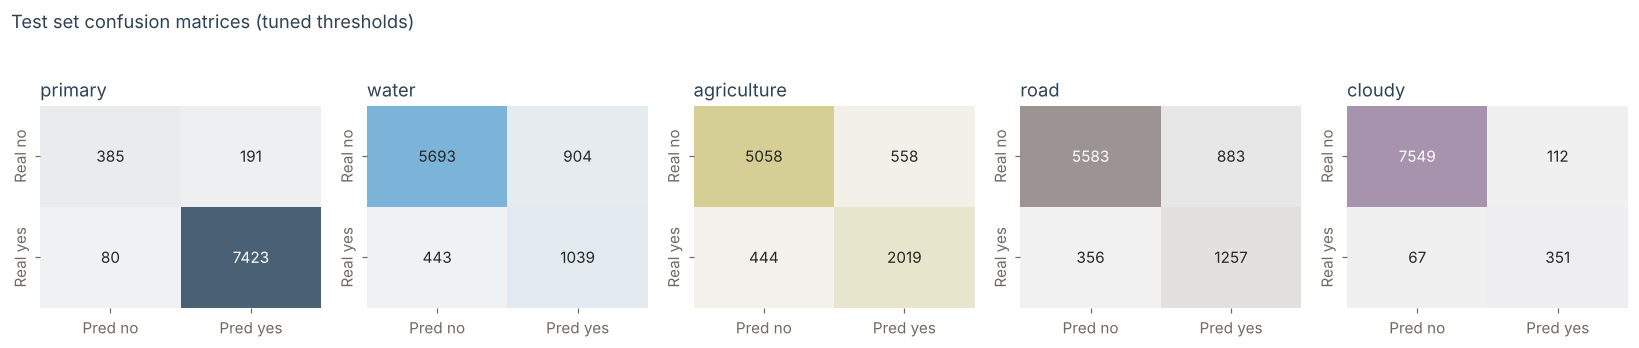

In [17]:
mcm = multilabel_confusion_matrix(Y_test, Y_pred_final)
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, lbl, cm in zip(axes, TARGET_LABELS, mcm):
    cmap = sns.light_palette(COLORS[lbl], as_cmap=True)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax, annot_kws={'size': 10},
                xticklabels=['Pred no', 'Pred yes'], yticklabels=['Real no', 'Real yes'])
    ax.set_title(lbl, loc='left')
plt.suptitle('Test set confusion matrices (tuned thresholds)', x=0.01, ha='left', y=1.04)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig6_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Anomaly score: recognising images unlike the training data

The Isolation Forest isolates unusual points with few random splits. In the demo we use it to warn the user when an image does not look like a Planet chip of the Amazon. The warning limit is the 99th percentile of the training scores: only 1 training image in 100 is more unusual.

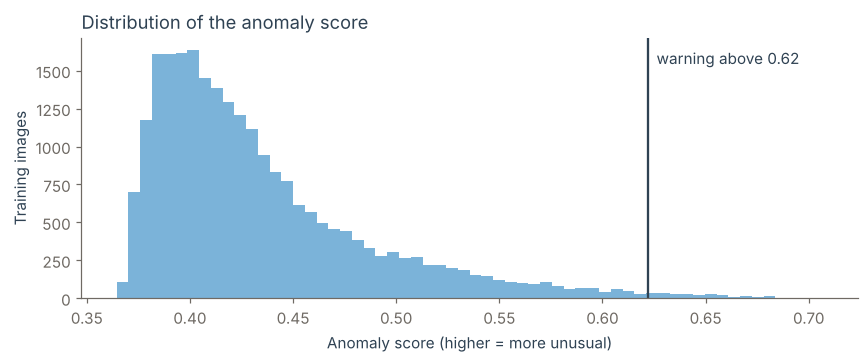

In [18]:
train_scores = score(X_train).ravel()
ANOMALY_LIMIT = float(np.percentile(train_scores, 99))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(train_scores, bins=60, color='#7BB3D9')
ax.axvline(ANOMALY_LIMIT, color=INK, linewidth=1.5)
ax.text(ANOMALY_LIMIT, ax.get_ylim()[1] * 0.9, f'  warning above {ANOMALY_LIMIT:.2f}', color=INK)
ax.set_xlabel('Anomaly score (higher = more unusual)'); ax.set_ylabel('Training images')
ax.set_title('Distribution of the anomaly score', loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig7_anomaly_score.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Which features matter

A Random Forest can tell us how much each feature reduces impurity across all its trees. This is the main advantage over a neural network: we can name the signals behind each prediction.

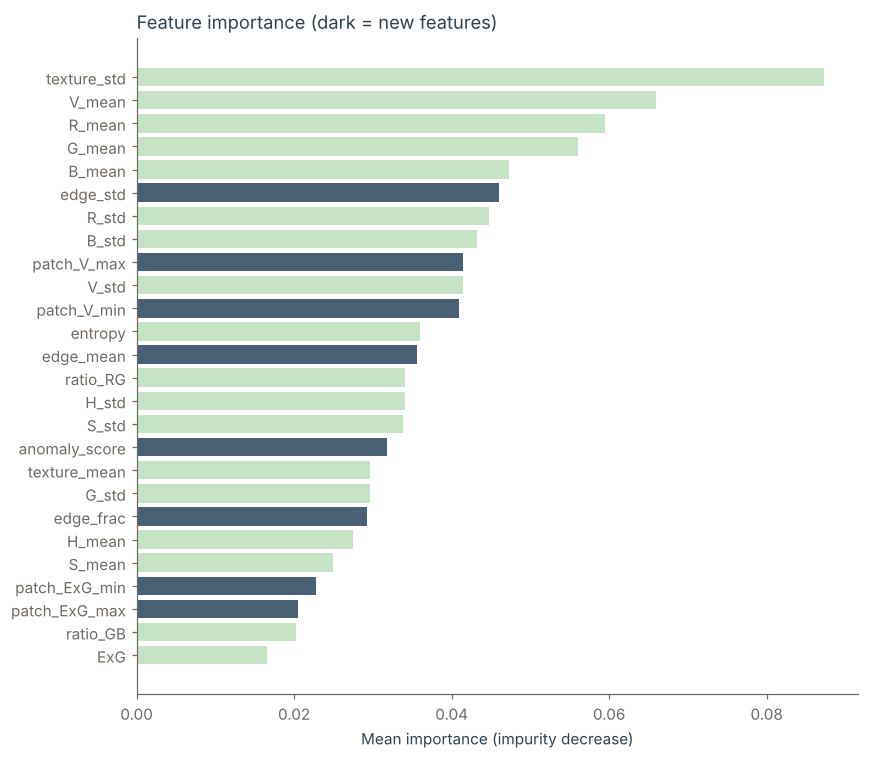

Top 5: ['texture_std', 'V_mean', 'R_mean', 'G_mean', 'B_mean']


In [19]:
importances = np.mean([est.feature_importances_ for est in final_model.estimators_], axis=0)
order = np.argsort(importances)

new = set(FEATURE_NAMES[G:]) | {'anomaly_score'}
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh([feat_names[i] for i in order], importances[order],
        color=['#4A6175' if feat_names[i] in new else MIST for i in order])
ax.set_xlabel('Mean importance (impurity decrease)')
ax.set_title('Feature importance (dark = new features)', loc='left')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig8_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Top 5:', [feat_names[i] for i in order[::-1][:5]])

## 12. Export for the demo

The demo (`demo/app.py`) needs the scaler, the Isolation Forest, the Random Forest and a small config with the thresholds. The forest is compressed so it fits on GitHub.

In [20]:
joblib.dump(final_model, MODEL_DIR / 'rf_balanced.joblib', compress=('lzma', 3))
joblib.dump(scaler,      MODEL_DIR / 'scaler.joblib')
joblib.dump(iso,         MODEL_DIR / 'isolation_forest.joblib')
(MODEL_DIR / 'config.json').write_text(json.dumps({
    'labels': TARGET_LABELS,
    'features': feat_names,
    'thresholds': thresholds,
    'anomaly_limit': round(ANOMALY_LIMIT, 4),
}, indent=2))

for f in sorted(MODEL_DIR.iterdir()):
    print(f'{f.name:<26} {f.stat().st_size / 1024 / 1024:6.1f} MB')

config.json                   0.0 MB
isolation_forest.joblib       1.1 MB
rf_balanced.joblib           25.0 MB
scaler.joblib                 0.0 MB
